<a href="https://colab.research.google.com/github/yashuu-2026/LLM_embeddibngs_learningphase/blob/main/salary_prediction_linear.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

importing libraries

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score

In [ ]:
import pandas as pd

df = pd.read_csv("/content/Salary Data.csv")
df.dropna(inplace=True) #inplace --> save changes in same df
df.isnull().sum()
df.dropna(inplace=True) #inplace --> save changes in same df
df.isnull().sum()

,0
Age,0
Gender,0
Education Level,0
Job Title,0
Years of Experience,0
Salary,0


In [ ]:
df.isnull().sum()

,0
Age,0
Gender,0
Education Level,0
Job Title,0
Years of Experience,0
Salary,0


In [ ]:
df.drop_duplicates(inplace=True)

print("number of duplicated after dropping:", df.duplicated().sum())

number of duplicated after dropping: 0


In [ ]:
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score

In [ ]:
print(df.isnull().sum())
df.dropna()

Age                    0
Gender                 0
Education Level        0
Job Title              0
Years of Experience    0
Salary                 0
dtype: int64


,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0
...,...,...,...,...,...,...
348,28.0,Female,Bachelor's,Junior Operations Manager,1.0,35000.0
349,36.0,Male,Bachelor's,Senior Business Development Manager,8.0,110000.0
350,44.0,Female,PhD,Senior Data Scientist,16.0,160000.0
351,31.0,Male,Bachelor's,Junior Marketing Coordinator,3.0,55000.0


outlier

<Axes: ylabel='Age'>

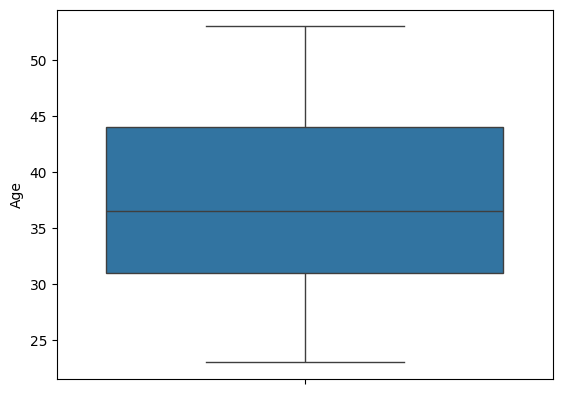

In [ ]:
sns.boxplot(df["Age"])

In [ ]:
GE = LabelEncoder()+
df["Gender_encoded"] = GE.fit_transform(df["Gender"])
df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary,Gender_encoded
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0,1
1,28.0,Female,Master's,Data Analyst,3.0,65000.0,0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0,1
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0,0
4,52.0,Male,Master's,Director,20.0,200000.0,1


In [ ]:
EE = LabelEncoder()
df["Education Level_encoded"] = EE.fit_transform(df["Education Level"])
df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary,Gender_encoded,Education Level_encoded
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0,1,0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0,0,1
2,45.0,Male,PhD,Senior Manager,15.0,150000.0,1,2
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0,0,0
4,52.0,Male,Master's,Director,20.0,200000.0,1,1


separate dependant and independant

In [ ]:
x = df[["Age","Years of Experience", "Gender_encoded","Education Level_encoded"]]
y = df["Salary"]
print("Feature shape:",x.shape)
print("Target shape:",y.shape)

Feature shape: (324, 4)
Target shape: (324,)


In [ ]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)


In [ ]:
print("Records for training: ", len(x_train))
print("Records for testing: ", len(x_test))

Records for training:  259
Records for testing:  65


apply scaling

In [ ]:
num_cols = ["Age" , "Years of Experience"]
my_scaler = StandardScaler()
x_train[num_cols] = my_scaler.fit_transform(x_train[num_cols])
x_test[num_cols] = my_scaler.transform(x_test[num_cols])
print(x_train)

          Age  Years of Experience  Gender_encoded  Education Level_encoded
73  -1.324980            -1.226813               1                        0
182  0.877474             0.714752               0                        2
17   0.189207             0.266698               1                        2
24   0.464514             0.416049               1                        1
146  0.602167             0.864103               0                        2
..        ...                  ...             ...                      ...
189 -1.324980            -1.301488               1                        0
71   0.189207             0.117347               0                        0
106 -1.049673            -1.077461               0                        0
284 -0.361406            -0.181355               1                        0
102  1.565740             1.312156               0                        1

[259 rows x 4 columns]


In [ ]:
Salary_model = LinearRegression()
Salary_model.fit(x_train,y_train)

LinearRegression()

In [ ]:
y_pred = Salary_model.predict(x_test)
result = pd.DataFrame({"Actual":y_test,"Predicted":y_pred})
result.head()

,Actual,Predicted
132,100000.0,116136.607289
108,100000.0,124667.619930
137,50000.0,49205.367039
9,110000.0,127707.611369
181,105000.0,106510.651731


In [ ]:
age = int(input("Enter your age: "))
yoe = int(input("Enter your years of experience: "))
gen = input("Enter gender (Male,Female): ")
el = input("Enter education: Bachelor's,Master's,PhD: ")

Enter your age: 21
Enter your years of experience: 3
Enter gender (Male,Female): Female
Enter education: Bachelor's,Master's,PhD: PhD


In [ ]:
gender_encoded = GE.transform([gen])[0]
education_encoded = EE.transform([el])[0]

In [ ]:
gen=GE.transform([gen])[0]
el=EE.transform([el])[0]

In [ ]:
age, yoe, gender_encoded, education_encoded

(21, 3, np.int64(0), np.int64(2))

In [ ]:
result = Salary_model.predict([[age, yoe, gender_encoded, education_encoded]])
print("Predicted Salary:", result)

Predicted Salary: [616777.26548767]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [ ]:
import numpy as np
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print("MAE:" , mae)

MAE: 10547.125753940905


since r2 score is approx 0.9 we can say the model covers or explains 90% of patters and variations in salary based on age,years of experince,gender,education level